# Kalimantan and Sumatera FIRMS fire alerts and fire count grid, August to October 2026

Plots the provinces of Kalimantan and mainland Sumatera on a basemap, the FIRMS fire alerts made by `job/firms` (VIIRS and MODIS near real time, clipped to each province), the fire count grids made by `job/firms_grid` (number of alerts per cell, with sea, outside the provinces and WorldCover water masked), and the number of alerts per regency and city (admin level 2). Both regions are shown together on each map.

In [1]:
import os

os.chdir(os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebook" else os.getcwd())

import contextily as cx
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from dotenv import load_dotenv
from matplotlib.colors import LogNorm
from matplotlib.ticker import FuncFormatter

# override=True so the .env credentials win over anything already in the environment
load_dotenv(override=True)

# Lower resolution figures, keeps the notebook small
plt.rcParams["figure.dpi"] = 60

AOI_URL = "/vsicurl/https://storage.googleapis.com/gee-ramiqcom-bucket/admin/indonesia_adm_level_1.fgb"
AOI2_URL = "/vsicurl/https://storage.googleapis.com/gee-ramiqcom-bucket/admin/indonesia_adm_level_2.fgb"

# Kalimantan and mainland Sumatera provinces, the same as job/firms
AOI_FILTER = (
    "WADMPR LIKE 'Kalimantan%' OR WADMPR LIKE 'Sumatera%' "
    "OR WADMPR IN ('Aceh', 'Riau', 'Jambi', 'Bengkulu', 'Lampung')"
)
CLOUD_PREFIX = "gs://gee-ramiqcom-s4g-bucket/forest_fire_indonesian_2026"
DATE_NAME = "2026-08_2026-10"
GRID_PATHS = {
    region: f"{CLOUD_PREFIX}/firms_grid/{region}_{DATE_NAME}.tif" for region in ["kalimantan", "sumatera"]
}
# Wide figure, both regions side by side span about twice as much longitude as latitude
FIGSIZE = (22, 11)

## Map helpers

In [2]:
def add_lonlat(ax):
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{abs(x):.2f}°{'E' if x >= 0 else 'W'}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{abs(y):.2f}°{'N' if y >= 0 else 'S'}"))
    ax.tick_params(labelsize=8)
    ax.grid(color="white", linewidth=0.4, alpha=0.6, linestyle="--")


def add_north_arrow(ax, x=0.94, y=0.92):
    ax.annotate(
        "N",
        xy=(x, y),
        xytext=(x, y - 0.1),
        xycoords="axes fraction",
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
        arrowprops=dict(facecolor="black", edgecolor="white", width=4, headwidth=12),
    )


def add_scalebar(ax, x=0.05, y=0.05):
    # Axes are in degrees, so convert km to degrees of longitude at the map's center latitude
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    km_per_deg = 111.32 * np.cos(np.radians((ymin + ymax) / 2))
    width_km = (xmax - xmin) * km_per_deg
    length_km = next(n for n in (500, 200, 100, 50, 20, 10, 5, 2, 1, 0.5) if n <= width_km / 4)
    length_deg = length_km / km_per_deg

    x0 = xmin + x * (xmax - xmin)
    y0 = ymin + y * (ymax - ymin)
    height = (ymax - ymin) * 0.012
    for i in range(2):
        ax.add_patch(
            plt.Rectangle(
                (x0 + i * length_deg / 2, y0),
                length_deg / 2,
                height,
                facecolor="black" if i == 0 else "white",
                edgecolor="black",
                linewidth=0.8,
            )
        )
    for frac in (0, 0.5, 1):
        ax.text(
            x0 + frac * length_deg,
            y0 + height * 1.6,
            f"{length_km * frac:g}",
            ha="center",
            va="bottom",
            fontsize=8,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1),
        )
    ax.text(x0 + length_deg + (xmax - xmin) * 0.01, y0, "km", va="bottom", fontsize=8)


def set_extent(ax, gdf, pad_frac=0.03):
    xmin, ymin, xmax, ymax = gdf.total_bounds
    pad = pad_frac * max(xmax - xmin, ymax - ymin)
    ax.set_xlim(xmin - pad, xmax + pad)
    ax.set_ylim(ymin - pad, ymax + pad)


def decorate(ax, title):
    add_lonlat(ax)
    add_north_arrow(ax)
    add_scalebar(ax)
    ax.set_title(title)

## 1. Kalimantan and Sumatera provinces

Province boundaries from the Indonesian admin level 1 file, the same source and filter as the jobs. The file stores each province as many polygon parts, dissolved here into one shape per province. Kepulauan Riau and Kepulauan Bangka Belitung are not included.

In [3]:
provinces = gpd.read_file(AOI_URL, where=AOI_FILTER, columns=["KDPPUM", "WADMPR"])
provinces = provinces.dissolve(by=["KDPPUM", "WADMPR"]).reset_index().to_crs("EPSG:4326")
provinces["province"] = provinces["WADMPR"].str.lower().str.replace(" ", "_")
provinces[["KDPPUM", "WADMPR"]]

,KDPPUM,WADMPR
0,11,Aceh
1,12,Sumatera Utara
2,13,Sumatera Barat
3,14,Riau
4,15,Jambi
5,16,Sumatera Selatan
6,17,Bengkulu
7,18,Lampung
8,61,Kalimantan Barat
9,62,Kalimantan Tengah


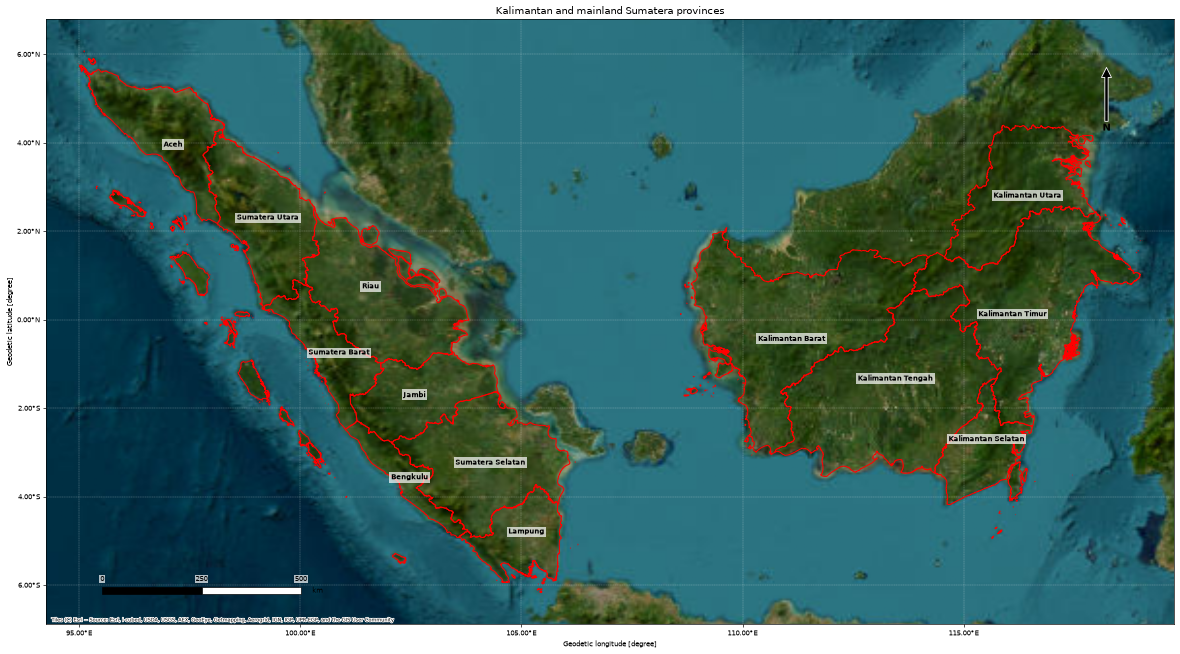

In [4]:
fig, ax = plt.subplots(figsize=FIGSIZE)

provinces.boundary.plot(ax=ax, color="red", linewidth=1.2)
for _, row in provinces.iterrows():
    point = row.geometry.representative_point()
    ax.text(
        point.x,
        point.y,
        row["WADMPR"],
        ha="center",
        fontsize=8,
        fontweight="bold",
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=2),
    )

set_extent(ax, provinces)
cx.add_basemap(ax, crs=provinces.crs, source=cx.providers.Esri.WorldImagery, attribution_size=6)
decorate(ax, "Kalimantan and mainland Sumatera provinces")

plt.tight_layout()
plt.show()

## 2. FIRMS fire alerts

All alerts from the province files. Each point is the centre of a satellite pixel with an active fire detection (375 m for VIIRS, 1 km for MODIS), not a burned area. MODIS near real time has no data for early August, so MODIS points cover only part of the period.

In [5]:
firms = pd.concat(
    [
        gpd.read_file(
            f"{CLOUD_PREFIX}/firms/{province}_{DATE_NAME}.fgb", columns=["acq_date", "instrument", "satellite"]
        ).assign(province=province)
        for province in provinces["province"]
    ],
    ignore_index=True,
)
firms = gpd.GeoDataFrame(firms, crs="EPSG:4326")

print(f"{len(firms):,} alerts, {firms['acq_date'].min()} to {firms['acq_date'].max()}")
firms.groupby(["province", "instrument"]).size().unstack(fill_value=0)

1,142,979 alerts, 2026-08-01 to 2026-10-31


instrument,MODIS,VIIRS
province,,
aceh,8,1632
bengkulu,54,1428
jambi,1450,20036
kalimantan_barat,9260,220986
kalimantan_selatan,4049,80366
kalimantan_tengah,29040,507408
kalimantan_timur,5728,90828
kalimantan_utara,200,8201
lampung,1190,17449


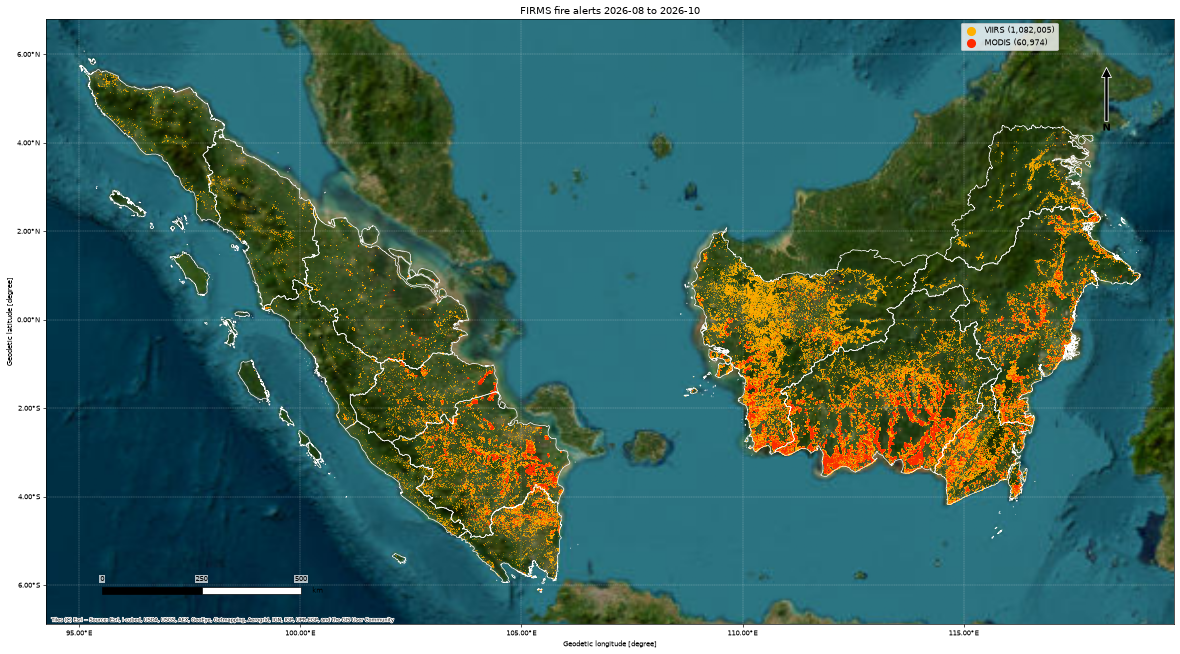

In [6]:
INSTRUMENT_COLORS = {"VIIRS": "#ffb000", "MODIS": "#ff2a00"}

fig, ax = plt.subplots(figsize=FIGSIZE)

# Scatter on the raw coordinates, much faster than GeoDataFrame.plot for millions of points
for instrument, color in INSTRUMENT_COLORS.items():
    points = firms[firms["instrument"] == instrument]
    ax.scatter(
        points.geometry.x,
        points.geometry.y,
        s=0.3,
        color=color,
        linewidths=0,
        label=f"{instrument} ({len(points):,})",
        rasterized=True,
    )
provinces.boundary.plot(ax=ax, color="white", linewidth=0.8)

set_extent(ax, provinces)
cx.add_basemap(ax, crs=provinces.crs, source=cx.providers.Esri.WorldImagery, attribution_size=6)
decorate(ax, f"FIRMS fire alerts {DATE_NAME.replace('_', ' to ')}")
ax.legend(loc="upper right", bbox_to_anchor=(0.9, 1), markerscale=20, fontsize=9)

plt.tight_layout()
plt.show()

## 3. Fire count grid

Number of FIRMS alerts per grid cell from `job/firms_grid`, one grid per region drawn on the same map with one color scale. The grid count only includes alerts within half a cell from the cell centre, so it counts fewer alerts than the points above. Cells with no alerts (0) are shown as no data, as are the masked sea, outside the provinces and WorldCover water cells. Log color scale because a few cells have far more alerts than the rest.

In [7]:
grids = {}
for region, path in GRID_PATHS.items():
    with rasterio.open(path) as src:
        grid = src.read(1)
        bounds = src.bounds
        nodata = src.nodata
        resolution = src.res

    # Masked cells and cells without alerts are not shown
    fire_count = np.ma.masked_where((grid == nodata) | (grid == 0), grid)
    grids[region] = (fire_count, (bounds.left, bounds.right, bounds.bottom, bounds.top))

    print(
        f"{region}: cell size {resolution[0]:.4f}°, {fire_count.count():,} cells with alerts, "
        f"{int(fire_count.sum()):,} alerts counted, max {fire_count.max()} per cell"
    )

# One color scale for both regions so they can be compared
grid_max = max(fire_count.max() for fire_count, _ in grids.values())

kalimantan: cell size 0.0090°, 88,055 cells with alerts, 749,840 alerts counted, max 721 per cell
sumatera: cell size 0.0090°, 23,915 cells with alerts, 146,599 alerts counted, max 469 per cell


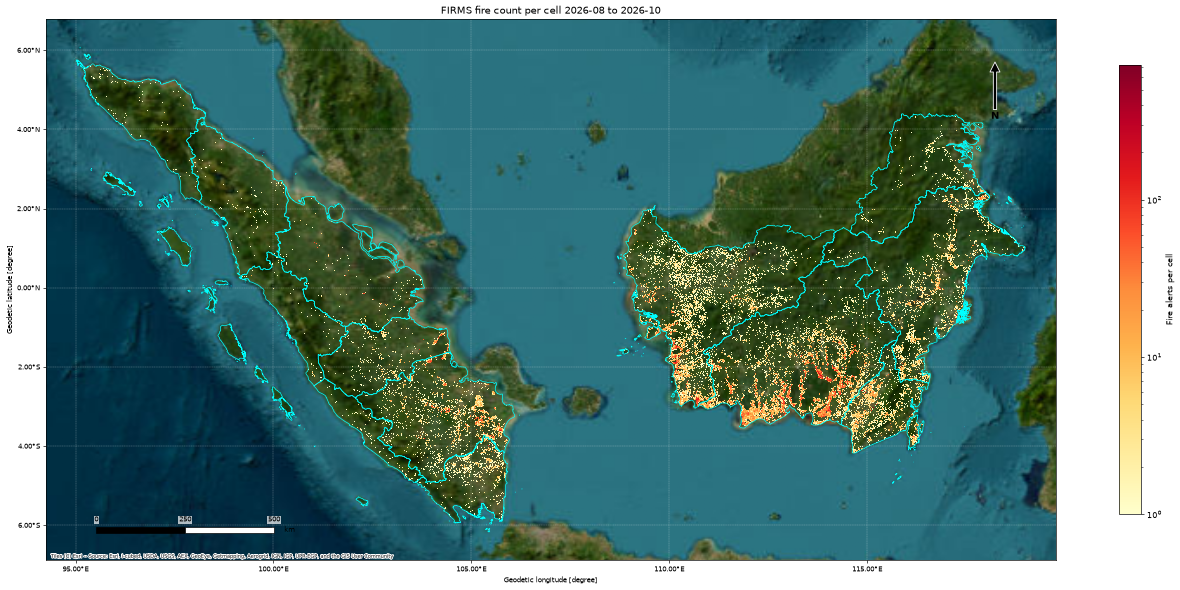

In [8]:
fig, ax = plt.subplots(figsize=FIGSIZE)

for fire_count, extent in grids.values():
    image = ax.imshow(
        fire_count,
        extent=extent,
        cmap="YlOrRd",
        norm=LogNorm(vmin=1, vmax=grid_max),
        interpolation="nearest",
        zorder=2,
    )
provinces.boundary.plot(ax=ax, color="cyan", linewidth=0.8, zorder=3)

set_extent(ax, provinces)
cx.add_basemap(ax, crs=provinces.crs, source=cx.providers.Esri.WorldImagery, attribution_size=6, zorder=1)
decorate(ax, f"FIRMS fire count per cell {DATE_NAME.replace('_', ' to ')}")
fig.colorbar(image, ax=ax, shrink=0.7, label="Fire alerts per cell")

plt.tight_layout()
plt.show()

## 4. Fire alerts per regency and city

Regency and city boundaries (kabupaten and kota) from the Indonesian admin level 2 file, with the same province filter. Each FIRMS alert is assigned to the regency it falls in, so every alert is counted, unlike the grid above. Regencies differ a lot in size, so the alerts per 100 km² are shown below the total count, with the area computed in an equal area projection (EPSG:6933). A few unnamed admin level 2 polygons are dropped by the dissolve.

In [9]:
regencies = gpd.read_file(AOI2_URL, where=AOI_FILTER, columns=["KDPKAB", "KDPPUM", "WADMKK", "WADMPR"])
regencies = regencies.dissolve(by=["KDPKAB", "KDPPUM", "WADMKK", "WADMPR"]).reset_index().to_crs("EPSG:4326")

alerts = firms[["instrument", "geometry"]].sjoin(regencies[["KDPKAB", "geometry"]], predicate="within")
counts = alerts.groupby(["KDPKAB", "instrument"]).size().unstack(fill_value=0)

regencies = regencies.merge(counts, left_on="KDPKAB", right_index=True, how="left")
regencies[["VIIRS", "MODIS"]] = regencies[["VIIRS", "MODIS"]].fillna(0).astype(int)
regencies["alerts"] = regencies["VIIRS"] + regencies["MODIS"]
regencies["area_km2"] = regencies.to_crs("EPSG:6933").area / 1e6
regencies["alerts_per_100km2"] = regencies["alerts"] / regencies["area_km2"] * 100

# Alerts near the coast or on borders can fall outside every admin level 2 polygon
print(f"{len(regencies)} regencies and cities, {regencies['alerts'].sum():,} of {len(firms):,} alerts assigned")
regencies.sort_values("alerts", ascending=False)[
    ["WADMKK", "WADMPR", "VIIRS", "MODIS", "alerts", "area_km2", "alerts_per_100km2"]
].head(20).round(1)

196 regencies and cities, 1,142,979 of 1,142,979 alerts assigned


,WADMKK,WADMPR,VIIRS,MODIS,alerts,area_km2,alerts_per_100km2
143,Ketapang,Kalimantan Barat,131369,6621,137990,30018.7,459.7
164,Pulang Pisau,Kalimantan Tengah,97928,6118,104046,9650.9,1078.1
156,Kapuas,Kalimantan Tengah,73694,3912,77606,17041.2,455.4
155,Kotawaringin Timur,Kalimantan Tengah,71439,3827,75266,15543.8,484.2
160,Seruyan,Kalimantan Tengah,65397,3960,69357,15215.2,455.8
99,Ogan Komering Ilir,Sumatera Selatan,54925,4494,59419,17071.3,348.1
159,Katingan,Kalimantan Tengah,48447,3039,51486,20382.3,252.6
154,Kotawaringin Barat,Kalimantan Tengah,48409,2997,51406,9480.3,542.2
167,Kota Palangkaraya,Kalimantan Tengah,46344,1784,48128,2848.7,1689.5
181,Paser,Kalimantan Timur,23770,1665,25435,10767.4,236.2


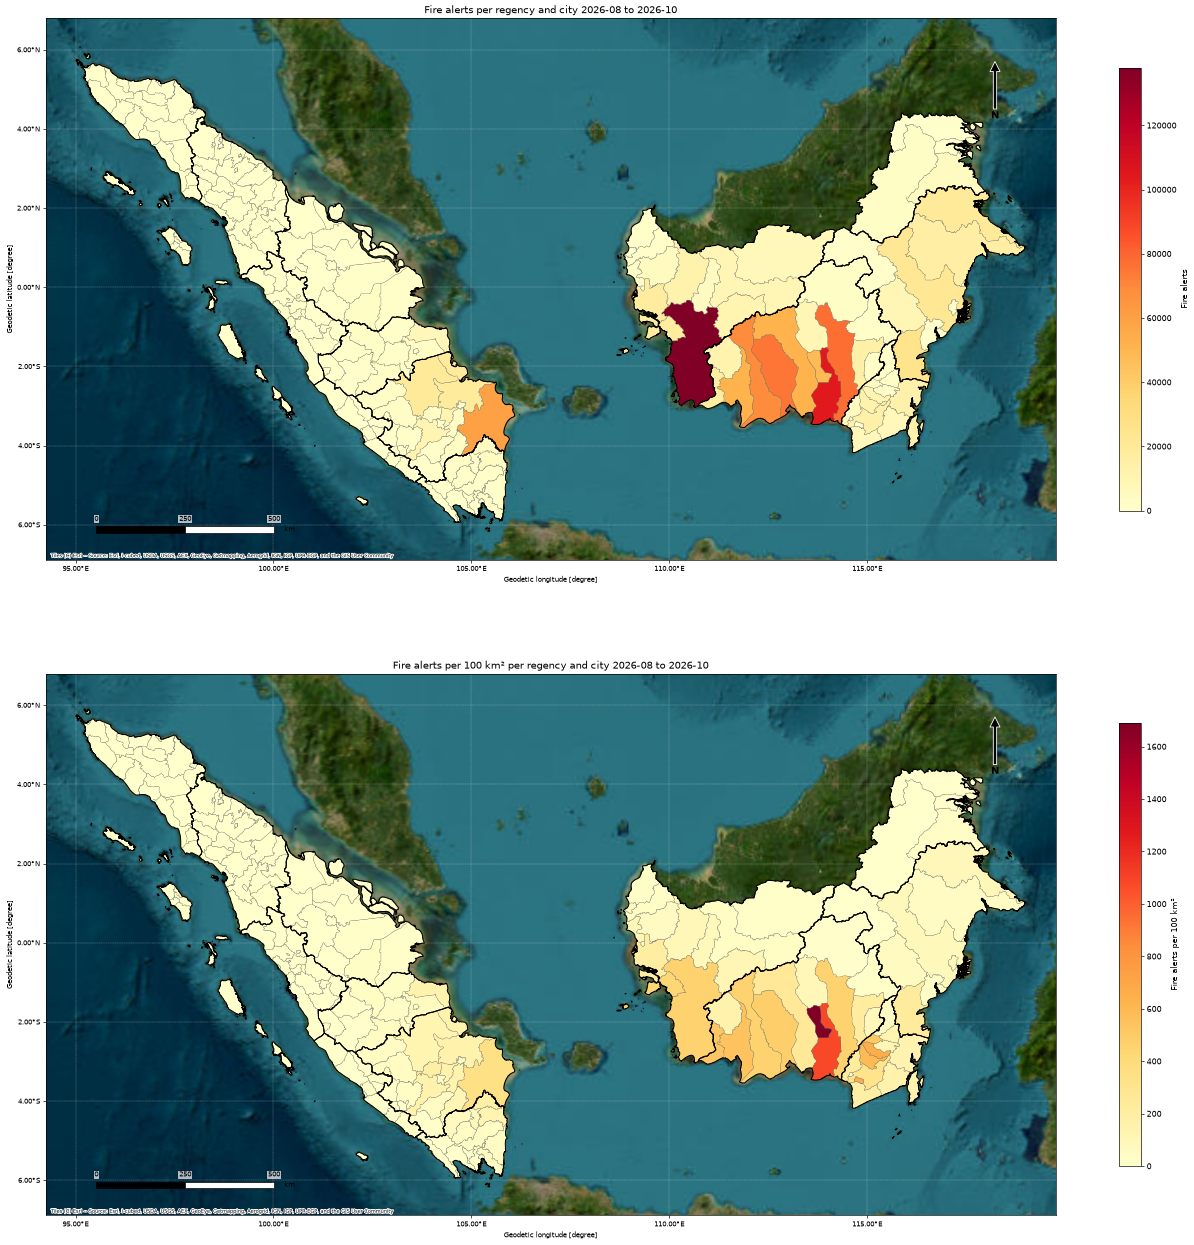

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(FIGSIZE[0], FIGSIZE[1] * 2))

for ax, (column, label, cmap) in zip(
    axes,
    [
        ("alerts", "Fire alerts", "YlOrRd"),
        ("alerts_per_100km2", "Fire alerts per 100 km²", "YlOrRd"),
    ],
):
    regencies.plot(
        ax=ax,
        column=column,
        cmap=cmap,
        edgecolor="grey",
        linewidth=0.3,
        legend=True,
        legend_kwds=dict(shrink=0.7, label=label),
        zorder=2,
    )
    provinces.boundary.plot(ax=ax, color="black", linewidth=1.2, zorder=3)

    set_extent(ax, provinces)
    cx.add_basemap(ax, crs=provinces.crs, source=cx.providers.Esri.WorldImagery, attribution_size=6, zorder=1)
    decorate(ax, f"{label} per regency and city {DATE_NAME.replace('_', ' to ')}")

plt.tight_layout()
plt.show()